# 1 · How efficiently do OIC economies turn capital and labour into output?
**Data Envelopment Analysis** builds a non-parametric best-practice frontier from the data itself, with no production function assumed. Each year, every country is compared with a frontier formed by **all countries in the Penn World Table**:

* **Inputs:** physical capital stock (`rnna`) and human-capital-adjusted employment (`emp × hc`)
* **Output:** real GDP (`rgdpna`)
* **Models:** input-oriented CCR (constant returns) and BCC (variable returns); **scale efficiency** = CCR / BCC

The 57 member states of the **Organisation of Islamic Cooperation (OIC)** are then examined. *The same toolkit applies at firm level, e.g. working-capital efficiency with receivable, inventory and payable days as inputs.*

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
pwt = pd.read_csv("../data/pwt1001_subset.csv.gz")
oic = pd.read_csv("../data/oic_members.csv")
pwt = pwt[(pwt.year >= 2000)].dropna(subset=["rgdpna", "rnna", "emp", "hc"])
pwt = pwt[(pwt.emp > 0.1)]                                   # drop micro-states (< 100k workers)
pwt["labour_hc"] = pwt.emp * pwt.hc                          # human-capital-adjusted labour
pwt["oic"] = pwt.countrycode.isin(oic.iso3)
print(f"{pwt.countrycode.nunique()} countries ({pwt[pwt.oic].countrycode.nunique()} OIC members), {pwt.year.min()}-{pwt.year.max()}")
from effpanel import dea

144 countries (41 OIC members), 2000-2019


In [2]:
rows = []
for yr, g in pwt.groupby("year"):
    g = g.set_index("countrycode")
    s = dea.scale_efficiency(g[["rnna", "labour_hc"]], g[["rgdpna"]])
    s["year"] = yr; rows.append(s)
eff = pd.concat(rows).reset_index(names="countrycode").merge(pwt[["countrycode", "country", "year", "oic"]], on=["countrycode", "year"])
eff.to_csv("../data/dea_scores.csv", index=False)
latest = eff[eff.year == eff.year.max()]
summary = latest.groupby("oic")[["CRS (technical)", "VRS (pure technical)", "scale"]].mean()
summary.index = ["Non-OIC", "OIC"]; summary.round(3)

,CRS (technical),VRS (pure technical),scale
Non-OIC,0.569,0.635,0.908
OIC,0.606,0.655,0.935


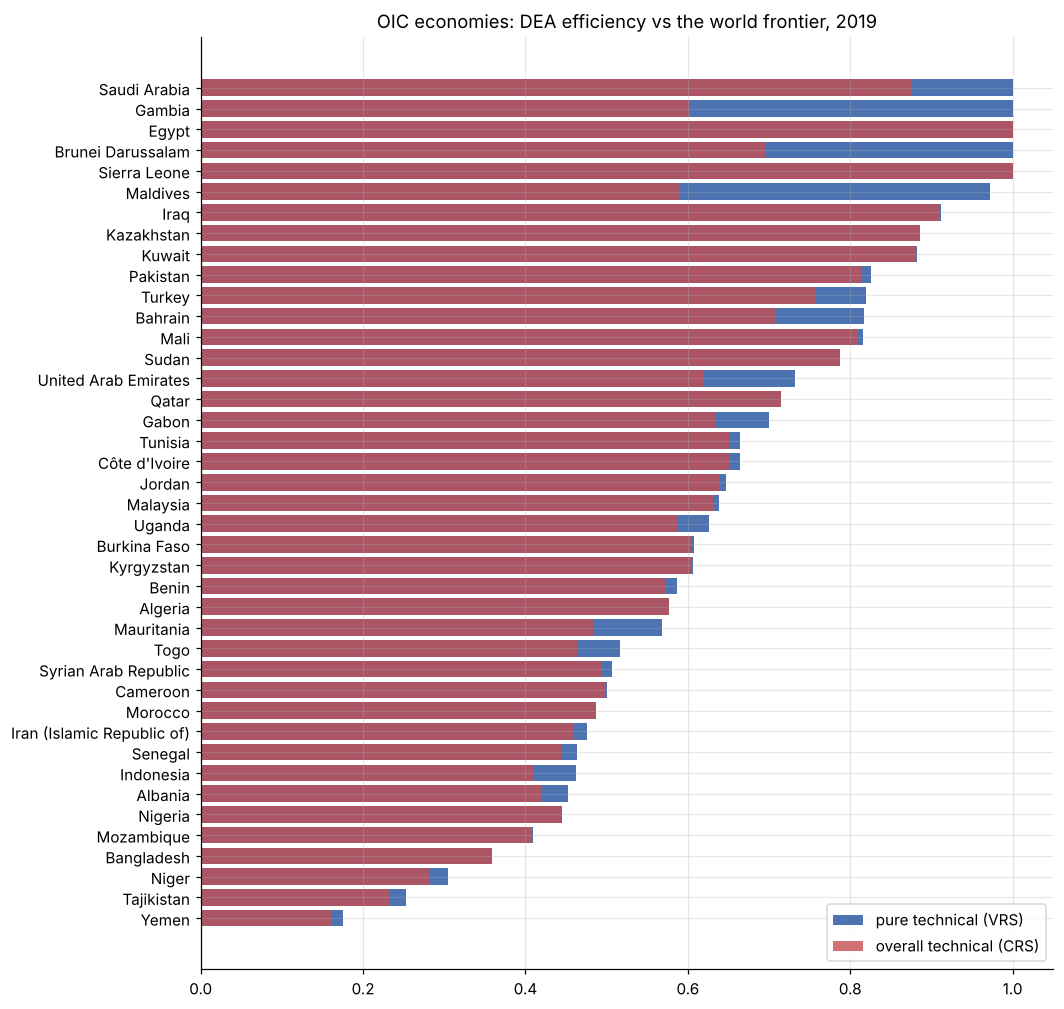

In [3]:
o = latest[latest.oic].sort_values("VRS (pure technical)")
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(o.country, o["VRS (pure technical)"], color="#4C72B0", label="pure technical (VRS)")
ax.barh(o.country, o["CRS (technical)"], color="#C44E52", alpha=0.8, label="overall technical (CRS)")
ax.set_title(f"OIC economies: DEA efficiency vs the world frontier, {int(eff.year.max())}"); ax.legend(loc="lower right")
plt.savefig(IMG / "oic_efficiency_ranking.png", bbox_inches="tight"); plt.show()

In [4]:
frontier = latest[latest["CRS (technical)"] > 0.999].country.tolist()
print("Countries on the CRS frontier:", ", ".join(frontier))
g = pwt[pwt.year == eff.year.max()].set_index("countrycode")
peers = dea.efficiency(g[["rnna", "labour_hc"]], g[["rgdpna"]], "vrs")
sel = [c for c in ["PAK", "IDN", "MYS", "TUR", "EGY", "BGD", "NGA", "SAU"] if c in g.index]
name = pwt.drop_duplicates("countrycode").set_index("countrycode").country
pd.DataFrame({"VRS score": peers.loc[sel, "score"].values, "benchmark peers": [", ".join(name[p] for p in ps) for ps in peers.loc[sel, "peers"]]},
             index=name[sel].values).round(3)

Countries on the CRS frontier: Egypt, Ireland, China, Macao SAR, Malawi, Sierra Leone


,VRS score,benchmark peers
Pakistan,0.826,"Egypt, Malawi"
Indonesia,0.462,"Egypt, United States"
Malaysia,0.638,"Egypt, Ireland, United States"
Turkey,0.820,"Ireland, Saudi Arabia, United States"
Egypt,1.000,Egypt
Bangladesh,0.359,"Egypt, Malawi"
Nigeria,0.445,"Egypt, Malawi"
Saudi Arabia,1.000,Saudi Arabia


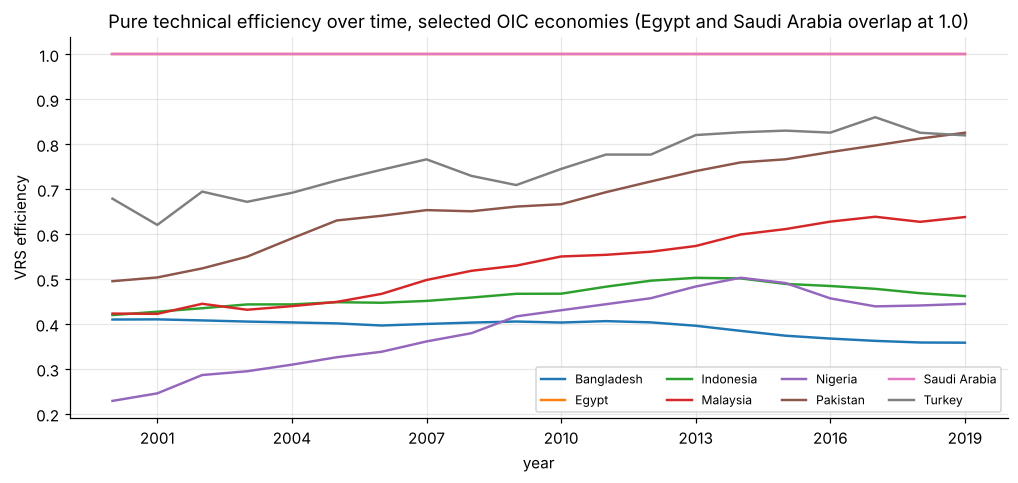

In [5]:
sel_names = name[sel]
pv = eff[eff.countrycode.isin(sel)].pivot(index="year", columns="countrycode", values="VRS (pure technical)").rename(columns=sel_names)
ax = pv.plot(figsize=(11, 4.5), lw=1.6)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.set_title("Pure technical efficiency over time, selected OIC economies (Egypt and Saudi Arabia overlap at 1.0)"); ax.set_ylabel("VRS efficiency"); ax.legend(ncol=4, fontsize=8)
plt.savefig(IMG / "efficiency_trends.png", bbox_inches="tight"); plt.show()

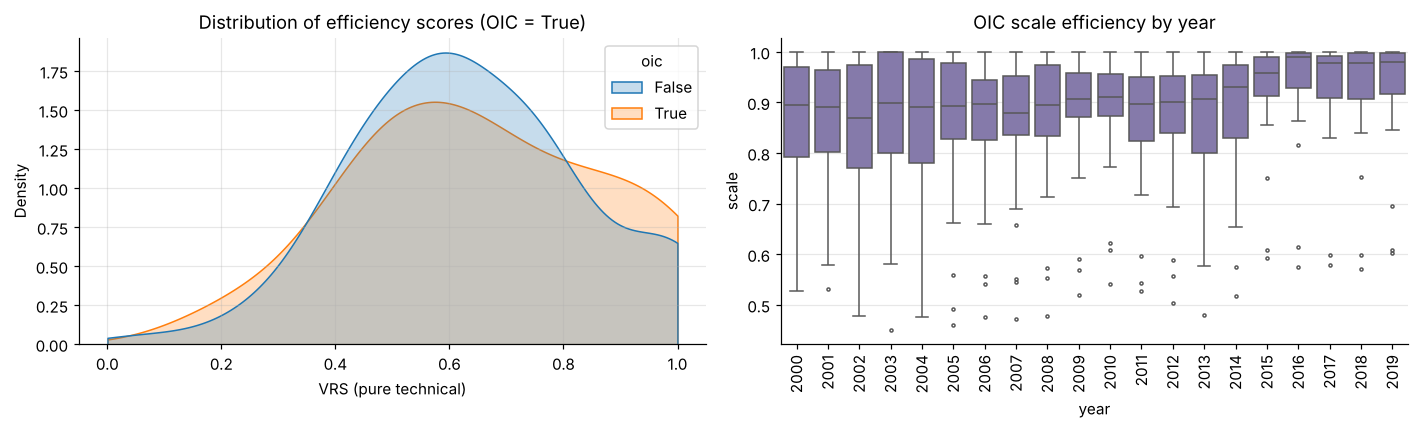

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=latest, x="VRS (pure technical)", hue="oic", common_norm=False, fill=True, ax=ax[0], clip=(0, 1))
ax[0].set_title("Distribution of efficiency scores (OIC = True)")
sns.boxplot(data=eff[eff.oic], x="year", y="scale", ax=ax[1], color="#8172B2", fliersize=2)
ax[1].set_title("OIC scale efficiency by year"); ax[1].tick_params(axis="x", rotation=90)
fig.tight_layout(); plt.show()

**Reading the scores.** A score of 0.6 means the country could, in principle, produce its current GDP with 60% of its capital and effective labour, if it operated like its frontier peers. *Pure technical* (VRS) inefficiency points to management and institutions; *scale* inefficiency points to an economy that is too small or too large for its input mix. DEA is deterministic and sensitive to outliers and measurement error, so notebook 3 checks which country characteristics are robustly associated with the scores. **Caveat visible in the results:** low-income economies such as Malawi and Sierra Leone sit on the CRS frontier. Their *measured* capital stocks are very small relative to output, and DEA treats that as efficiency. Because the frontier is built from extreme observations, measurement error in capital-stock estimates feeds straight into everyone's scores. In applied work, check robustness with bootstrapped DEA (Simar & Wilson, 1998) or order-m frontiers.